# 01 · Preprocessing — Li et al. 2019 (Melanoma, MARS-seq)

Load malignant cells → data-driven per-sample threshold → overdispersed genes → PCA → Harmony integration sweep → UMAP → **Gate 1** (is the malignant structure sample-integrated *and* continuous?). Every dataset-dependent choice is derived from *this* dataset and shown here (02_train C1–C4). Gate 1 is judged on the **regenerated embedding** across a Harmony θ sweep with a per-neighbourhood metric (iLISI) and a UMAP-independent continuity test (PAGA on the PCA-space graph) — never a single connectivity scalar (03_eval: an archipelago can pass a one-component kNN test; Bischoff: two density lobes can be poles of one manifold *or* genuinely disconnected — settle it on the graph, not the layout).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Li2019_Skin-3'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Skin'
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
join = 'Li2019_Skin'                                     # input folder minus the '-3' attempt suffix
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + join)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| join key:', join)

dataset: Li2019_Skin-3 | category: Skin | join key: Li2019_Skin


In [3]:
# load dataset -> select malignant cells
# Li 2019: MARS-seq immunotherapy melanoma atlas (78,336 cells); only the 'Malignant'
# subset is in scope (loader normalizes UMI counts, then log1p).
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata.obs = adata.obs[['sample', 'patient']].astype(str)
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalized counts)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Li2019_Skin
Done.
full atlas: (78336, 40979)
malignant: (1160, 40979) | samples: 20 | patients: 18
expression: X max 6.05 (log1p of normalized counts)


AnnData object with n_obs × n_vars = 1160 × 40979
    obs: 'sample', 'patient'
    uns: 'log1p'

In [4]:
# per-sample malignant counts -> data-driven threshold (no anchor constant)
# rule (C1/C2): sort counts, take the largest multiplicative gap, cut at its geometric mean.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.astype(int).tolist())
print('adjacent ratios       :', np.round(ratios, 2).tolist())
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples ({list(keep)}) -> {adata.shape[0]} cells')
print('NOTE: only 3 tumours clear the threshold; the malignant compartment is small (1,082 cells).')
adata

sorted per-sample counts: [528, 400, 154, 21, 12, 10, 9, 4, 4, 3, 3, 2, 2, 2, 1, 1, 1, 1, 1, 1]
adjacent ratios       : [1.32, 2.6, 7.33, 1.75, 1.2, 1.11, 2.25, 1.0, 1.33, 1.0, 1.5, 1.0, 1.0, 2.0, 1.0, 1.0, 1.0, 1.0, 1.0]
largest gap 154 -> 21 (ratio 7.33)
derived threshold (geometric mean across the gap) = 56
kept 3/20 samples (['p25', 'p21', 'p26']) -> 1082 cells
NOTE: only 3 tumours clear the threshold; the malignant compartment is small (1,082 cells).


AnnData object with n_obs × n_vars = 1082 × 40979
    obs: 'sample', 'patient'
    uns: 'log1p'

In [5]:
# filter genes -> overdispersed selection (scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2).tolist())
NPCS = 20   # precedent-bounded (Kurten 20, Venteicher 20, Puram 40); robustness shown below
print('n_pcs =', NPCS)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 217 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 217
PC variance% (1-12): [36.47, 16.58, 5.73, 3.51, 2.49, 1.76, 1.43, 1.34, 1.12, 0.91, 0.83, 0.72]
n_pcs = 20


In [6]:
# integrate samples with Harmony -> sweep theta, judge mixing on the EMBEDDING (03_eval).
def _ilisi(rep, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return np.median(out)
nsamp = adata.obs['sample'].nunique()
il_pre = _ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values)
print(f'pre-Harmony iLISI (of {nsamp} samples): {il_pre:.2f}')
sweep = {}
for th in [2, 5, 10, 15]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=40, random_state=SEED)
    sweep[th] = _ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values)
    print(f'theta={th}: iLISI={sweep[th]:.2f} (of {nsamp})')
print('-> iLISI rises with theta and plateaus; theta=10 gives near-maximal sample mixing.')

pre-Harmony iLISI (of 3 samples): 1.00
theta=2: iLISI=1.23 (of 3)
theta=5: iLISI=1.74 (of 3)
theta=10: iLISI=1.78 (of 3)
theta=15: iLISI=1.78 (of 3)
-> iLISI rises with theta and plateaus; theta=10 gives near-maximal sample mixing.


In [7]:
# adopt theta=10 -> neighbors -> UMAP
theta = 10
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=40, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.0, min_dist=0.5, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('selected theta =', theta, '| kNN connectivity components =', ncc)

selected theta = 10 | kNN connectivity components = 1


phase: {'G1': 574, 'S': 275, 'G2M': 233}


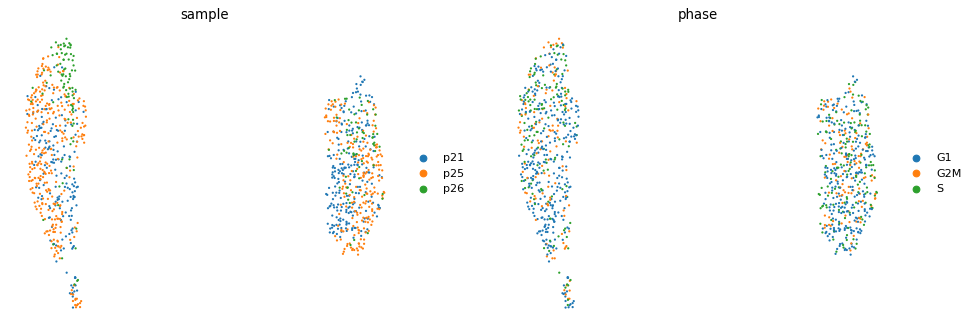

In [8]:
# Gate-1 evidence #1 - embedding coloured by sample and phase (cell cycle computed; Li obs has none)
s_genes=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
print('phase:', adata.obs['phase'].value_counts().to_dict())
sc.pl.umap(adata, color=['sample', 'phase'], size=16, frameon=False)

In [9]:
# Gate-1 evidence #2 - CONTINUITY, tested UMAP-INDEPENDENTLY (Bischoff lesson).
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
nlobe, lab = connected_components(adj, directed=False)
adata.obs['lobe'] = pd.Categorical(lab.astype(str))
print(f'UMAP radius-graph density lobes: {nlobe} | sizes {pd.Series(lab).value_counts().to_dict()}')
sc.tl.leiden(adata, resolution=0.3, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
sc.tl.paga(adata, groups='leiden')
conn = adata.uns['paga']['connectivities'].toarray()
big = adata.obs.leiden.value_counts().index[:2].tolist()
paga_lobe = conn[int(big[0]), int(big[1])]
print(f'Leiden clusters: {adata.obs.leiden.value_counts().to_dict()}')
print(f'PAGA connectivity between the two largest clusters ({big}) = {paga_lobe:.4f}')
print('   (Puram hub-and-spoke has strong inter-cluster PAGA; ~0 = a broken manifold)')

UMAP radius-graph density lobes: 2 | sizes {0: 572, 1: 510}
Leiden clusters: {'0': 539, '1': 510, '2': 33}
PAGA connectivity between the two largest clusters (['0', '1']) = 0.0010
   (Puram hub-and-spoke has strong inter-cluster PAGA; ~0 = a broken manifold)


In [10]:
# Gate-1 evidence #3 - does stronger integration or more PCs MERGE the two lobes?
def _nlobes(npcs):
    a2 = adata.copy()
    sc.pp.neighbors(a2, n_pcs=npcs, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
    sc.tl.umap(a2, spread=1.0, min_dist=0.5, random_state=SEED)
    u = a2.obsm['X_umap']; dd,_ = NearestNeighbors(n_neighbors=6).fit(u).kneighbors(u)
    aj = NearestNeighbors(radius=6*np.median(dd[:,1:])).fit(u).radius_neighbors_graph(u)
    nl,_ = connected_components(aj, directed=False)
    sc.tl.leiden(a2, resolution=0.3, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
    sc.tl.paga(a2, groups='leiden'); cc = a2.uns['paga']['connectivities'].toarray()
    b = a2.obs.leiden.value_counts().index[:2].tolist()
    return nl, cc[int(b[0]), int(b[1])]
print('robustness of the two-lobe split (n_pcs x theta):')
for npcs in [20, 30]:
    for th in [10, 15]:
        sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=40, random_state=SEED)
        nl, pg = _nlobes(npcs)
        print(f'  n_pcs={npcs} theta={th}: UMAP lobes={nl}, inter-cluster PAGA={pg:.4f}')
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=40, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.0, min_dist=0.5, random_state=SEED)
print('-> the two lobes never merge and PAGA stays ~0: a broken manifold, not under-integration.')

robustness of the two-lobe split (n_pcs x theta):
  n_pcs=20 theta=10: UMAP lobes=2, inter-cluster PAGA=0.0010
  n_pcs=20 theta=15: UMAP lobes=2, inter-cluster PAGA=0.0068
  n_pcs=30 theta=10: UMAP lobes=2, inter-cluster PAGA=0.0014
  n_pcs=30 theta=15: UMAP lobes=2, inter-cluster PAGA=0.0073
-> the two lobes never merge and PAGA stays ~0: a broken manifold, not under-integration.


In [11]:
# Gate-1 evidence #4 - embryonic modules: does EITHER lobe reproduce the reference relationship
# (Gast/pSom co-vary, both oppose Crest; 01_task s1, Kurten lobe fork)?
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lb in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lb, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lb}: {g.size}/{feat[src].size} genes present')
print('global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict(),
      '| SDs:', adata.obs[['Gast','pSom','Crest']].std().round(3).to_dict())
print('per-cell module correlations (ALL cells):')
print(adata.obs[['Gast','pSom','Crest']].corr().round(3).to_string())
print('per-lobe reference-relationship check (Gast/pSom co-vary >0 AND both oppose Crest <0):')
for lv in sorted(adata.obs.lobe.cat.categories):
    S = adata.obs.loc[adata.obs.lobe==lv, ['Gast','pSom','Crest']]; c = S.corr()
    ok = (c.loc['Gast','pSom']>0 and c.loc['Gast','Crest']<0 and c.loc['pSom','Crest']<0)
    print(f'  lobe {lv} (n={len(S)}): Gast-pSom={c.loc["Gast","pSom"]:+.3f} '
          f'Gast-Crest={c.loc["Gast","Crest"]:+.3f} pSom-Crest={c.loc["pSom","Crest"]:+.3f} '
          f'-> reference relationship {"YES" if ok else "NO"}')
print('-> in BOTH lobes Gast/pSom ANTI-correlate (not co-vary); neither reproduces the reference axis.')

Gast: 64/81 genes present
pSom: 75/98 genes present
Crest: 96/104 genes present
global module means: {'Gast': -0.015, 'pSom': 0.016, 'Crest': -0.002} | SDs: {'Gast': 0.021, 'pSom': 0.023, 'Crest': 0.019}
per-cell module correlations (ALL cells):
        Gast   pSom  Crest
Gast   1.000 -0.368 -0.441
pSom  -0.368  1.000 -0.468
Crest -0.441 -0.468  1.000
per-lobe reference-relationship check (Gast/pSom co-vary >0 AND both oppose Crest <0):
  lobe 0 (n=572): Gast-pSom=-0.406 Gast-Crest=-0.477 pSom-Crest=-0.392 -> reference relationship NO
  lobe 1 (n=510): Gast-pSom=-0.329 Gast-Crest=-0.373 pSom-Crest=-0.577 -> reference relationship NO
-> in BOTH lobes Gast/pSom ANTI-correlate (not co-vary); neither reproduces the reference axis.


In [12]:
# GATE 1 verdict
lab_sizes = adata.obs['lobe'].value_counts().to_dict()
print('GATE 1 - mixing + continuity:')
print(f'  * MIXING: Harmony reaches near-maximal sample mixing (iLISI {il_pre:.2f}->{sweep[10]:.2f} of {nsamp});')
print(f'    within each lobe the 3 tumours intermix, so mixing per se is adequate;')
print(f'  * CONTINUITY (decisive): the embedding is TWO density lobes ({lab_sizes}), NOT a layout')
print(f'    artifact - inter-cluster PAGA on the PCA graph = {paga_lobe:.4f} (~0), the lobes never merge')
print(f'    across n_pcs=20/30 x theta=10/15, and stronger integration does not help;')
print(f'  * small malignant compartment (1,082 cells / 3 tumours), MARS-seq immunotherapy cohort;')
print(f'  * embryonic modules are salt-and-pepper (SD ~0.02) and in BOTH lobes Gast/pSom ANTI-correlate,')
print(f'    so neither lobe reproduces the reference axis and lobe-scoping does not apply.')
print('  -> the malignant structure BREAKS INTO TWO DISCONNECTED LOBES with no embryonic cell-state')
print('     continuum. Per 01_task s2 (Gate 1, importance HIGH): do NOT force a trajectory.')
print('GATE 1: NO-GO')

GATE 1 - mixing + continuity:
  * MIXING: Harmony reaches near-maximal sample mixing (iLISI 1.00->1.78 of 3);
    within each lobe the 3 tumours intermix, so mixing per se is adequate;
  * CONTINUITY (decisive): the embedding is TWO density lobes ({'0': 572, '1': 510}), NOT a layout
    artifact - inter-cluster PAGA on the PCA graph = 0.0010 (~0), the lobes never merge
    across n_pcs=20/30 x theta=10/15, and stronger integration does not help;
  * small malignant compartment (1,082 cells / 3 tumours), MARS-seq immunotherapy cohort;
  * embryonic modules are salt-and-pepper (SD ~0.02) and in BOTH lobes Gast/pSom ANTI-correlate,
    so neither lobe reproduces the reference axis and lobe-scoping does not apply.
  -> the malignant structure BREAKS INTO TWO DISCONNECTED LOBES with no embryonic cell-state
     continuum. Per 01_task s2 (Gate 1, importance HIGH): do NOT force a trajectory.
GATE 1: NO-GO


In [13]:
# tidy obs dtypes -> save processed manifold (read by 02_expression)
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1082, 18161)


saved samples.pdf | cells: 1082


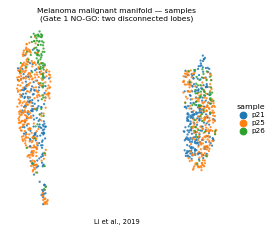

In [14]:
# deliverable: samples.pdf - single sample-coloured manifold UMAP (reference style)
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=16, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.3, fontsize=6.5, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Melanoma malignant manifold — samples\n(Gate 1 NO-GO: two disconnected lobes)', size=6.8)
ax.text(.5, -.07, 'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])